# Lab 2 – Predicting Diabetes Progression

In this lab I build models that predict how much a patient's diabetes progresses one year after their
first (baseline) visit. The idea is that a model like this could be used as a **screening tool**, so
doctors can spot patients who are at higher risk early.

The models I try are: polynomial regression on BMI only, multivariate polynomial regression, decision
trees, k-Nearest Neighbours (kNN) and logistic regression.

I compare them using **R²**, **Mean Absolute Error (MAE)** and **Mean Absolute Percentage Error (MAPE)**,
with a 75% / 10% / 15% train / validation / test split.

# Part 1 – Data
## 1. Get the data

I load the dataset with `load_diabetes` and use two of its options:
- `as_frame=True` so I get a pandas DataFrame with column names, instead of plain arrays.
- `scaled=False` so the features stay in their original units (for example BMI in kg/m² and age in
  years). By default sklearn scales every feature, which would make the BMI equation in Part 2 hard to
  read. With real units I can say things like "a BMI of 30 predicts ...".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

In [2]:
diabetes = datasets.load_diabetes(as_frame=True, scaled=False)
print(diabetes.DESCR[:1500])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

The six blood test columns are called `s1` to `s6`, which isn't very readable. I used the dataset
description to rename them to what they actually measure.

In [3]:
column_names = {
    "s1": "tc",   # total serum cholesterol
    "s2": "ldl",  # low-density lipoproteins
    "s3": "hdl",  # high-density lipoproteins
    "s4": "tch",  # total cholesterol / HDL
    "s5": "ltg",  # log of serum triglycerides level
    "s6": "glu",  # blood sugar level
}
df = diabetes.frame.rename(columns=column_names)
df.head()

,age,sex,bmi,bp,tc,ldl,hdl,tch,ltg,glu,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.860,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.892,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.673,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.890,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.290,80.0,135.0


In [4]:
df.shape

(442, 11)

## 2. Frame the problem

**What am I predicting?** The `target` column. It's a number that measures how much the disease
progressed one year after baseline. A higher number means the disease got worse.

**What am I predicting it from?** 10 measurements taken at baseline for 442 patients: age, sex, BMI,
average blood pressure and six blood serum measurements.

**Why does it matter?** If doctors can see early which patients are likely to get worse, they can start
treatment or monitor those patients more closely before the disease progresses.

**What type of problem is it?**
- It's **supervised learning**, because every patient has a known target value to learn from.
- The target is a continuous number, so it's mainly a **regression** problem. That's what the
  polynomial models, regression trees and kNN regression do.
- But screening is really a yes/no question: *is this patient high risk or not?* So I can also treat
  it as **binary classification** (high vs. low progression). That's how I use logistic regression in Part 3.

**Ideas from the workshops that apply here**
- *Performance metrics (classification):* for a screening tool, the worst mistake is a
  **false negative**, where a high-risk patient isn't flagged and doesn't get follow-up. A false
  positive only means an extra check-up. So **recall** matters more to me than plain accuracy. A
  confusion matrix shows both kinds of mistakes, and I can lower the decision threshold to catch more
  high-risk patients (at the cost of more false alarms).
- *k-Nearest Neighbours:* kNN predicts by averaging the *k* most similar patients. "Similar" is
  measured by distance, so I have to **scale** the features first. Otherwise large-valued features like
  cholesterol would dominate. A small *k* follows the training data very closely (it can overfit), and
  a large *k* gives smoother predictions (it can underfit).
- *Logistic regression:* this gives the **probability** that a patient is high risk, using the sigmoid
  function. That's useful for screening because a doctor can choose the probability cut-off, and the
  coefficients show which features raise or lower the risk.

**How I measure the regression models**
- **R²**: how much of the variation in the target the model explains. 1 is perfect, 0 means it's no
  better than guessing the average, and it can even be negative.
- **MAE**: the average size of the error, in the same units as the target.
- **MAPE**: the average error as a percentage of the true value. It gets very large when the true value
  is small.

**Baseline:** the simplest possible model just predicts the training average every time (this is the
degree-0 model in Part 2). Any model I build has to beat that to be useful.

## 3. Exploratory Data Analysis
### 3.1 Structure and descriptive statistics

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   tc      442 non-null    float64
 5   ldl     442 non-null    float64
 6   hdl     442 non-null    float64
 7   tch     442 non-null    float64
 8   ltg     442 non-null    float64
 9   glu     442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.518,13.109,19.000,38.250,50.00,59.000,79.000
sex,442.0,1.468,0.500,1.000,1.000,1.00,2.000,2.000
bmi,442.0,26.376,4.418,18.000,23.200,25.70,29.275,42.200
bp,442.0,94.647,13.831,62.000,84.000,93.00,105.000,133.000
tc,442.0,189.140,34.608,97.000,164.250,186.00,209.750,301.000
ldl,442.0,115.439,30.413,41.600,96.050,113.00,134.500,242.400
hdl,442.0,49.788,12.934,22.000,40.250,48.00,57.750,99.000
tch,442.0,4.070,1.290,2.000,3.000,4.00,5.000,9.090
ltg,442.0,4.641,0.522,3.258,4.277,4.62,4.997,6.107
glu,442.0,91.260,11.496,58.000,83.250,91.00,98.000,124.000


In [7]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nSex counts:\n", df["sex"].value_counts())
print("\nSkewness:\n", df.skew().round(2))

Missing values: 0
Duplicate rows: 0

Sex counts:
 sex
1.0    235
2.0    207
Name: count, dtype: int64

Skewness:
 age      -0.23
sex       0.13
bmi       0.60
bp        0.29
tc        0.38
ldl       0.44
hdl       0.80
tch       0.74
ltg       0.29
glu       0.21
target    0.44
dtype: float64


### 3.2 Distributions (histograms)

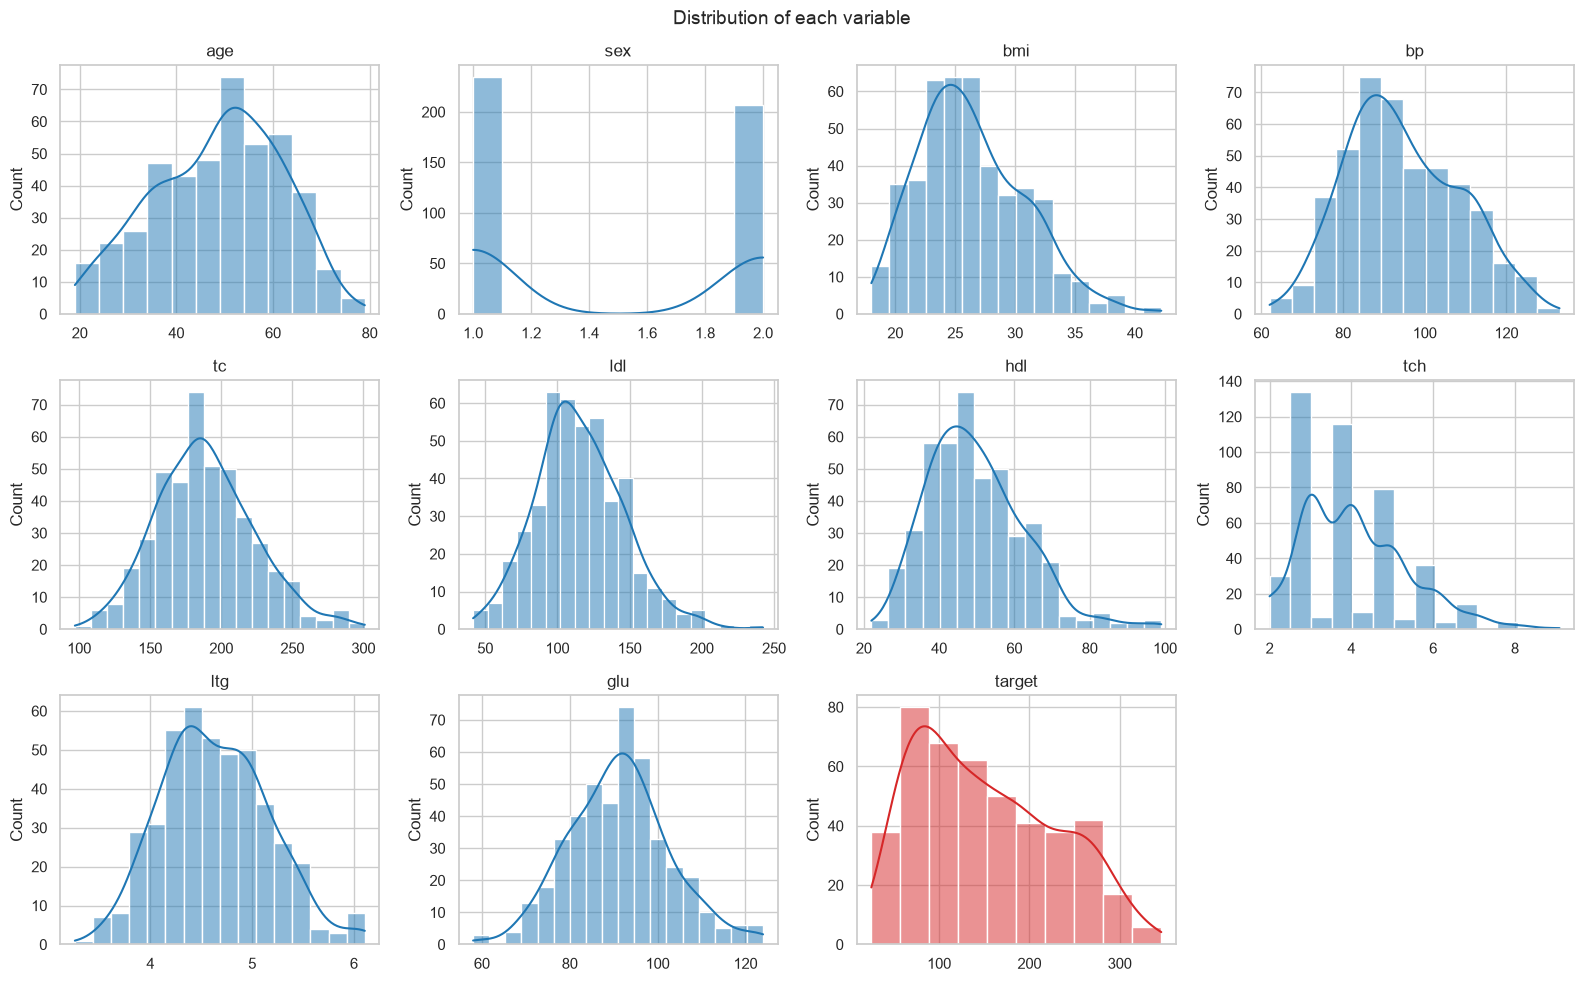

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color="tab:red" if col == "target" else "tab:blue")
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Distribution of each variable", fontsize=14)
fig.tight_layout()
plt.show()

### 3.3 Outliers (box plots, IQR rule)

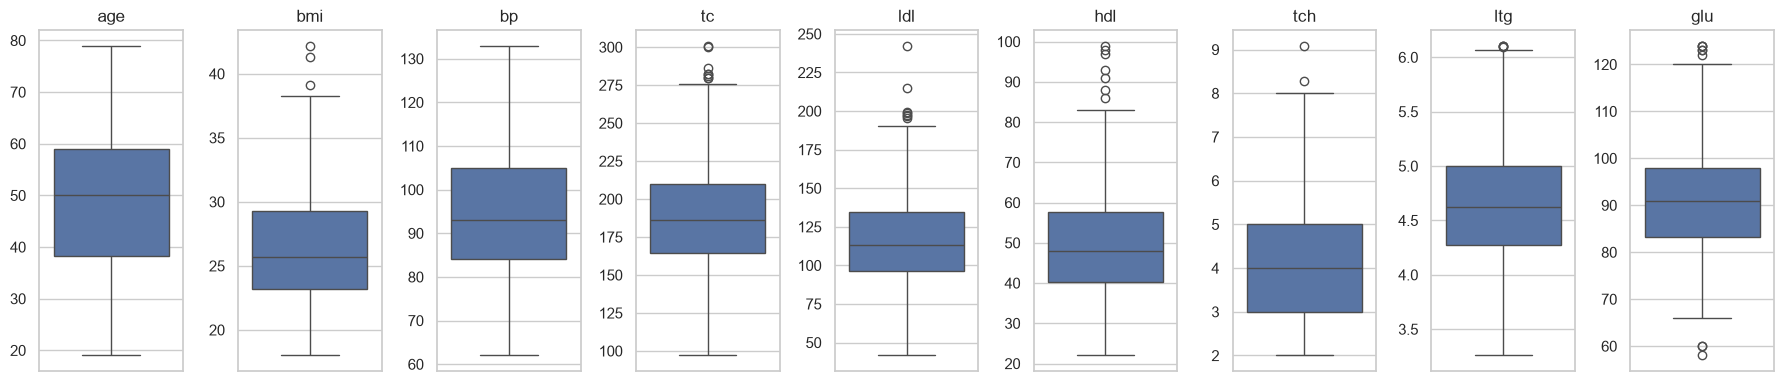

,age,bmi,bp,tc,ldl,hdl,tch,ltg,glu
IQR outliers,0,3,0,8,7,7,2,4,9


In [9]:
features = df.columns.drop(["target", "sex"])
fig, axes = plt.subplots(1, len(features), figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
outliers = ((df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)).sum()
outliers.rename("IQR outliers").to_frame().T

### 3.4 Each feature vs. the target (scatter plots)

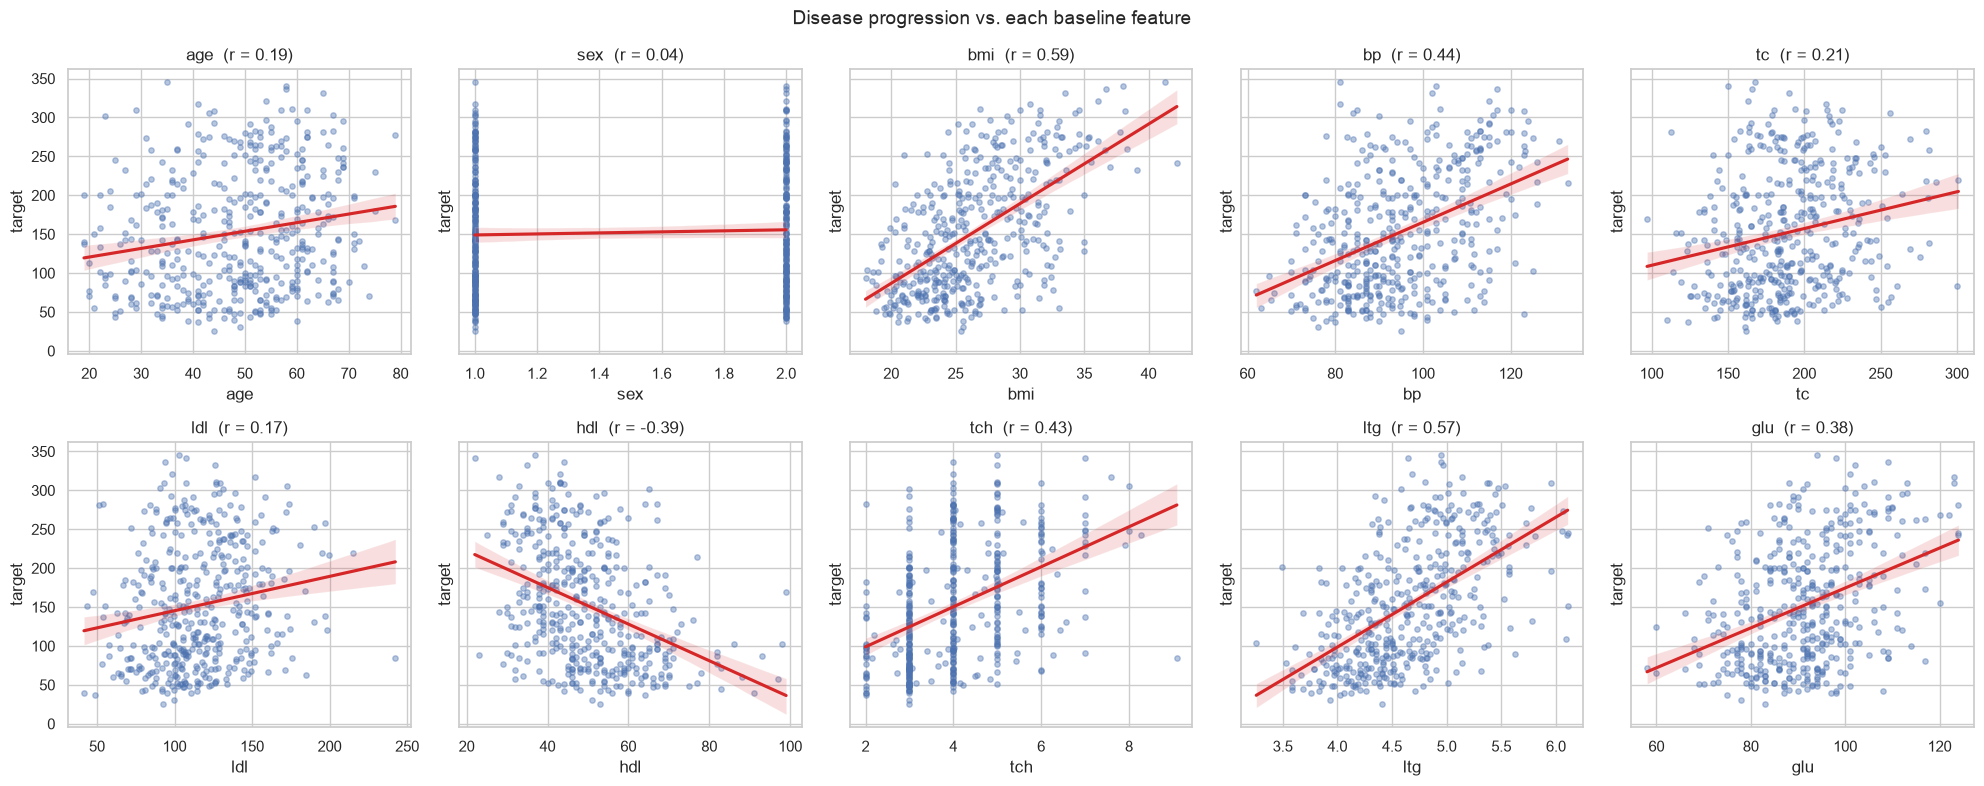

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=True)
for ax, col in zip(axes.flat, df.columns.drop("target")):
    sns.regplot(data=df, x=col, y="target", ax=ax, scatter_kws={"alpha": 0.4, "s": 15},
                line_kws={"color": "tab:red"})
    ax.set_title(f"{col}  (r = {df[col].corr(df['target']):.2f})")
fig.suptitle("Disease progression vs. each baseline feature", fontsize=14)
fig.tight_layout()
plt.show()

### 3.5 Correlation matrix

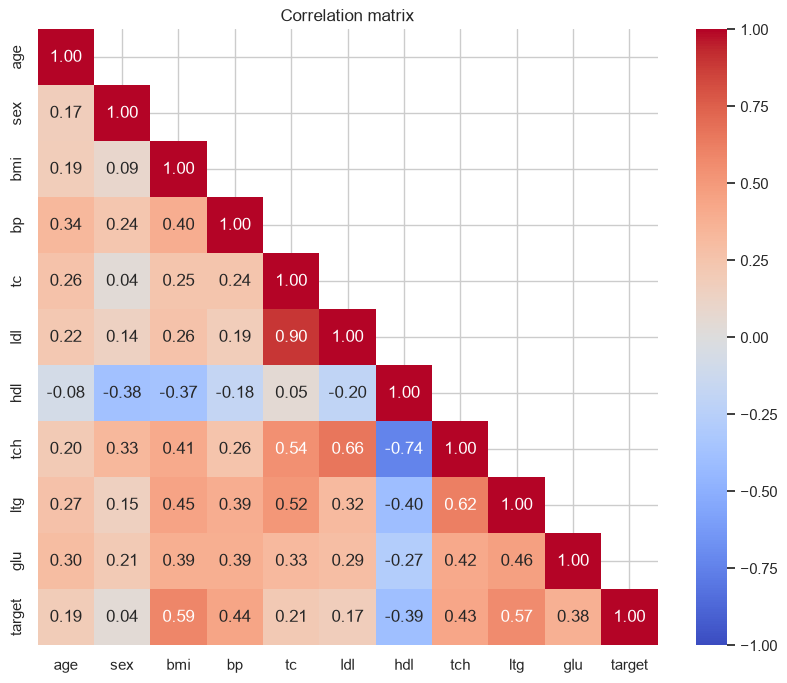

,corr with target
bmi,0.586
ltg,0.566
bp,0.441
tch,0.430
hdl,-0.395
glu,0.382
tc,0.212
age,0.188
ldl,0.174
sex,0.043


In [11]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
plt.title("Correlation matrix")
plt.show()

corr["target"].drop("target").sort_values(key=abs, ascending=False).to_frame("corr with target")

### 3.6 What I found in the EDA

- **The dataset is small but clean:** 442 patients, 10 numeric features, no missing values and no
  duplicate rows.
- **The target** goes from 25 to 346 (mean about 152, median about 140). It's skewed to the right, so
  there are fewer patients with very high progression. That means the models have fewer examples of
  the highest-risk patients to learn from.
- **Strongest features:** `bmi` (r = 0.59) and `ltg` (r = 0.57), then `bp` (0.44), `tch` (0.43),
  `hdl` (−0.39) and `glu` (0.38). `hdl` is negative, which makes sense because HDL is the "good"
  cholesterol. BMI is the strongest, which is why I use it in Part 2.
- **Weak features:** `sex` (0.04), `ldl` (0.17), `age` (0.19) and `tc` (0.21) have only a weak linear
  relationship with the target on their own.
- **Some features overlap:** `tc` and `ldl` have r = 0.90, so they carry almost the same information.
  `tch` is also strongly related to `hdl` (−0.74), `ldl` (0.66) and `ltg` (0.62), which makes sense
  because `tch` is itself a cholesterol ratio.
- **Scatter plots:** even BMI has a lot of spread around the trend line. So I don't expect one feature
  on its own to explain most of the variation (BMI's r² is only about 0.35).
- **The features are on very different scales** (for example `tc` is around 190 and `ltg` is around
  4.6), so I'll need to scale them for kNN.
- `tch` is mostly whole numbers from 2 to 7, so it behaves almost like a category. `hdl` and `tch` are
  the most right-skewed features.
- **There are only a few outliers** (at most 9 per feature using the IQR rule, mostly in `glu`, `tc`,
  `ldl` and `hdl`). The values look like real measurements, not typing mistakes.

## 4. Data cleaning

The EDA showed the data is already in good shape, so I didn't need to do much:

| Check | What I found | What I did |
|---|---|---|
| Missing values | none | nothing to fill in |
| Duplicate rows | none | nothing to remove |
| Outliers | a few, but realistic values | **kept them** – they're real patients, and with only 442 rows I don't want to throw data away |
| `sex` | coded as 1 and 2 | changed it to 0 and 1 so it works as a simple yes/no variable |
| Feature scales | very different | I scale inside each model's pipeline instead of here, so the scaler only learns from the training data (this avoids data leakage) |

I decide which features to use for the multivariate models at the start of Part 3.

In [12]:
df_clean = df.copy()
df_clean["sex"] = (df_clean["sex"] == 2).astype(int)

assert df_clean.isna().sum().sum() == 0
df_clean.describe().T[["min", "max", "mean"]]

,min,max,mean
age,19.000,79.000,48.518
sex,0.000,1.000,0.468
bmi,18.000,42.200,26.376
bp,62.000,133.000,94.647
tc,97.000,301.000,189.140
ldl,41.600,242.400,115.439
hdl,22.000,99.000,49.788
tch,2.000,9.090,4.070
ltg,3.258,6.107,4.641
glu,58.000,124.000,91.260


## 5. Train / validation / test split (75% / 10% / 15%)

I use `train_test_split` twice. First I take out 15% of the data as the test set. Then I split the
remaining 85% so that 10% of the *whole* dataset becomes the validation set (that's 10/85 of what's left).

- I use the **validation set** to compare the models and pick the best one.
- I only use the **test set** once, at the very end, on the model I picked. That way the test score is
  a fair estimate of how the model would do on new patients.

I also check that the target looks similar in all three sets.

In [13]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="target")
y = df_clean["target"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.10 / 0.85, random_state=RANDOM_STATE
)

split_sizes = pd.DataFrame(
    {"rows": [len(X_train), len(X_val), len(X_test)]}, index=["train", "validation", "test"]
)
split_sizes["share"] = (split_sizes["rows"] / len(X)).map("{:.1%}".format)
split_sizes

,rows,share
train,330,74.7%
validation,45,10.2%
test,67,15.2%


In [14]:
pd.DataFrame({"train": y_train.describe(), "validation": y_val.describe(), "test": y_test.describe()}).T

,count,mean,std,min,25%,50%,75%,max
train,330.0,153.045,78.035,25.0,86.25,142.0,211.5,346.0
validation,45.0,153.289,75.285,49.0,96.00,141.0,217.0,308.0
test,67.0,146.866,74.469,42.0,88.50,129.0,201.0,310.0


# Part 2 – Univariate polynomial regression on BMI
## 6. Models: degree 0 to 5

For each degree from 0 to 5, I make a pipeline of `PolynomialFeatures(degree)` followed by
`LinearRegression`.

`PolynomialFeatures` already adds a column of 1s (the bias), so I set `fit_intercept=False` in
`LinearRegression`. That way the intercept is just the weight on the column of 1s, and the number of
weights equals the number of features it creates. This makes counting parameters in step 13 easier.

Degree 0 has no BMI term at all, so it just predicts the training average every time. This is my **baseline**.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X_train_bmi, X_val_bmi, X_test_bmi = X_train[["bmi"]], X_val[["bmi"]], X_test[["bmi"]]

bmi_models = {}
for degree in range(6):
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=True)),
        ("linreg", LinearRegression(fit_intercept=False)),
    ])
    bmi_models[degree] = model.fit(X_train_bmi, y_train)

list(bmi_models)

[0, 1, 2, 3, 4, 5]

## 7. Compare the models on training and validation data

In [16]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error


def regression_metrics(y_true, y_pred):
    """R², MAE and MAPE (as a percentage) for one set of predictions."""
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
    }


def compare_models(models, X_tr, X_va):
    """One row per model with train and validation metrics side by side."""
    rows = {}
    for name, model in models.items():
        train = regression_metrics(y_train, model.predict(X_tr))
        val = regression_metrics(y_val, model.predict(X_va))
        rows[name] = {**{f"Train {k}": v for k, v in train.items()},
                      **{f"Val {k}": v for k, v in val.items()}}
    return pd.DataFrame(rows).T


bmi_results = compare_models(bmi_models, X_train_bmi, X_val_bmi)
bmi_results.index = [f"Degree {d}" for d in bmi_results.index]
bmi_results.round(3)

,Train R2,Train MAE,Train MAPE (%),Val R2,Val MAE,Val MAPE (%)
Degree 0,0.000,66.548,63.352,-0.000,63.447,58.793
Degree 1,0.354,52.278,48.462,0.449,41.998,40.445
Degree 2,0.355,52.267,48.448,0.449,41.758,40.310
Degree 3,0.355,52.239,48.395,0.448,41.765,40.291
Degree 4,0.355,52.243,48.398,0.448,41.737,40.276
Degree 5,0.355,52.231,48.408,0.449,41.802,40.321


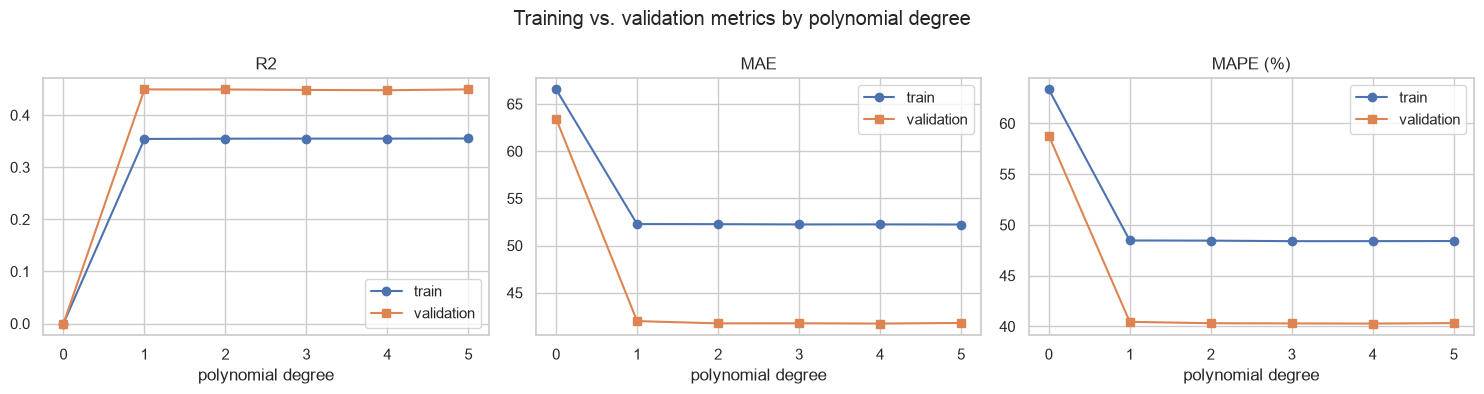

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["R2", "MAE", "MAPE (%)"]):
    ax.plot(range(6), bmi_results[f"Train {metric}"], "o-", label="train")
    ax.plot(range(6), bmi_results[f"Val {metric}"], "s-", label="validation")
    ax.set(title=metric, xlabel="polynomial degree")
    ax.legend()
fig.suptitle("Training vs. validation metrics by polynomial degree")
fig.tight_layout()
plt.show()

**What I noticed**
- **Degree 0 (the baseline)** has an R² of about 0, which is expected since it only predicts the mean.
- The only big jump is from degree 0 to degree 1. Validation R² goes from 0 to about 0.45, and MAE
  drops by about 21 points.
- **Degrees 2 to 5 are basically the same as degree 1** (they only differ in the third decimal place).
  So the relationship between BMI and progression looks linear, and the extra curves are just fitting noise.
- The validation scores are a bit *better* than the training scores. I don't think this is a problem.
  The validation set only has 45 patients and it happens to be a slightly easier sample. It does show
  that validation scores can bounce around.
- MAPE is high for every model (about 40–48%). Most of this comes from patients with low target values,
  where even a small error is a big percentage.

## 8. Identify the best model

In [18]:
pd.DataFrame({
    "best model": [bmi_results["Val R2"].idxmax(), bmi_results["Val MAE"].idxmin(),
                   bmi_results["Val MAPE (%)"].idxmin()],
    "value": [bmi_results["Val R2"].max(), bmi_results["Val MAE"].min(),
              bmi_results["Val MAPE (%)"].min()],
    "degree 1 value": bmi_results.loc["Degree 1", ["Val R2", "Val MAE", "Val MAPE (%)"]].values,
}, index=["Val R2", "Val MAE", "Val MAPE (%)"]).round(3)

,best model,value,degree 1 value
Val R2,Degree 5,0.449,0.449
Val MAE,Degree 4,41.737,41.998
Val MAPE (%),Degree 4,40.276,40.445


Each metric picks a slightly different "best" model, but they're all within **0.3 points of MAE,
0.2% of MAPE and 0.001 of R²** of degree 1. That's much smaller than the random variation I'd expect
from a validation set of only 45 patients.

When models perform the same, I go with the **simplest** one (Occam's razor). Degree 1 has the fewest
parameters, is the least likely to overfit, behaves more sensibly for unusual BMI values, and is the
easiest for a doctor to understand.

**I chose degree 1 (a straight line on BMI).**

In [19]:
BEST_DEGREE = 1
best_bmi_model = bmi_models[BEST_DEGREE]

## 9. Evaluate the chosen model on the test set

I haven't used the test set for any decisions yet, so this gives a fair estimate of how the model
would do on new patients.

In [20]:
bmi_test_results = pd.DataFrame({
    "train": regression_metrics(y_train, best_bmi_model.predict(X_train_bmi)),
    "validation": regression_metrics(y_val, best_bmi_model.predict(X_val_bmi)),
    "test": regression_metrics(y_test, best_bmi_model.predict(X_test_bmi)),
}).T
bmi_test_results.round(3)

,R2,MAE,MAPE (%)
train,0.354,52.278,48.462
validation,0.449,41.998,40.445
test,0.204,54.934,48.750


**Test results:** R² ≈ 0.20, MAE ≈ 55, MAPE ≈ 49%.

- The test score is clearly **worse than validation** (R² dropped from 0.45 to 0.20). The train and
  test MAE and MAPE are close to each other (about 52–55 and 48–49%), so I think the small validation
  set was just an easy sample, and the training numbers are closer to the real performance.
- A straight line can't really overfit, so I don't think the drop comes from overfitting. It's more
  likely random variation from having small splits. Cross-validation would give a more stable estimate.
- An average error of about 55 points (when the target's standard deviation is about 77) tells me that
  BMI on its own is a weak predictor.

## 10. Plot the train, validation and test data with the model fit

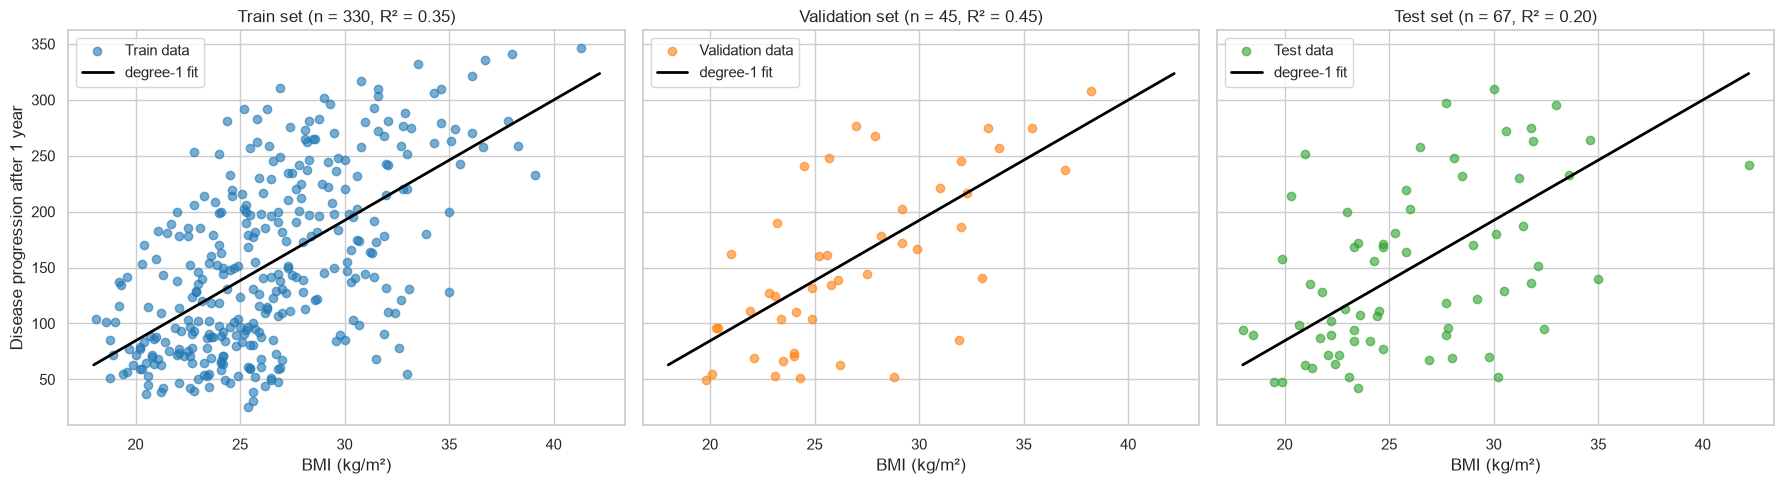

In [21]:
bmi_grid = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 200)})
bmi_fit = best_bmi_model.predict(bmi_grid)

splits = [("Train", X_train_bmi, y_train, "tab:blue"),
          ("Validation", X_val_bmi, y_val, "tab:orange"),
          ("Test", X_test_bmi, y_test, "tab:green")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (name, X_split, y_split, color) in zip(axes, splits):
    r2 = r2_score(y_split, best_bmi_model.predict(X_split))
    ax.scatter(X_split["bmi"], y_split, alpha=0.6, color=color, label=f"{name} data")
    ax.plot(bmi_grid["bmi"], bmi_fit, color="black", lw=2, label=f"degree-{BEST_DEGREE} fit")
    ax.set(title=f"{name} set (n = {len(y_split)}, R² = {r2:.2f})", xlabel="BMI (kg/m²)")
    ax.legend()
axes[0].set_ylabel("Disease progression after 1 year")
fig.tight_layout()
plt.show()

The line follows the upward trend in all three sets, but the points are very spread out around it.
For example, patients with a BMI between 24 and 26 have actual progression anywhere from 25 to 292.
The test set also has the most extreme BMI (about 42), and the line over-predicts for that patient.

## 11. Equation of the best model

In [22]:
feature_names = best_bmi_model.named_steps["poly"].get_feature_names_out()
coefs = best_bmi_model.named_steps["linreg"].coef_

terms = []
for name, coef in zip(feature_names, coefs):
    terms.append(f"{coef:.2f}" if name == "1" else f"{coef:.2f}·{name}")
equation = "progression = " + " + ".join(terms).replace("+ -", "- ")
print(equation)

progression = -130.87 + 10.77·bmi


$$\widehat{\text{progression}} = -130.87 + 10.77 \times \text{BMI}$$

- **Slope:** for every extra 1 kg/m² of BMI, the model predicts about 10.8 more points of progression
  after one year.
- **Intercept:** −130.87 is what the model would predict at BMI = 0, which isn't a real BMI. It just
  sets where the line sits, so I don't interpret it on its own. Within the BMI range in the data (18–42),
  the predictions go from about 63 to 323.

## 12. Predict progression for a chosen BMI value

I picked BMI = 30 kg/m² because that's the cut-off for obesity.

In [23]:
bmi_value = pd.DataFrame({"bmi": [30.0]})
predicted = best_bmi_model.predict(bmi_value)[0]
print(f"Predicted progression for BMI = {bmi_value['bmi'][0]}: {predicted:.2f}")
print(f"Check with the equation: {coefs[0] + coefs[1] * 30:.2f}")

Predicted progression for BMI = 30.0: 192.17
Check with the equation: 192.17


For a BMI of 30, the model predicts about 192. That's above the median (about 140), so this patient
would lean towards the higher-risk group. But since the test MAE is about 55, the real value could
easily be anywhere from about 137 to 247.

## 13. Number of trainable parameters per model

In [24]:
param_table = pd.DataFrame([
    {
        "model": f"Degree {degree}",
        "features (get_feature_names_out)": ", ".join(model.named_steps["poly"].get_feature_names_out()),
        "trainable parameters": model.named_steps["linreg"].coef_.size,
    }
    for degree, model in bmi_models.items()
]).set_index("model")
param_table

,features (get_feature_names_out),trainable parameters
model,,
Degree 0,1,1
Degree 1,"1, bmi",2
Degree 2,"1, bmi, bmi^2",3
Degree 3,"1, bmi, bmi^2, bmi^3",4
Degree 4,"1, bmi, bmi^2, bmi^3, bmi^4",5
Degree 5,"1, bmi, bmi^2, bmi^3, bmi^4, bmi^5",6


A degree-*d* polynomial in one variable, $\hat y = w_0 + w_1x + w_2x^2 + \dots + w_dx^d$, has
**d + 1 trainable parameters**: one weight for each power of BMI from $x^0$ (the column of 1s, which
is the intercept) up to $x^d$. So my six models have 1, 2, 3, 4, 5 and 6 parameters.

- Degree 0 only learns the intercept, which ends up being the training mean.
- My chosen degree-1 model learns 2: the intercept (−130.87) and the slope (10.77).
- The extra parameters in degrees 2–5 didn't improve the validation scores at all. More flexibility,
  but no benefit.

## 14. Conclusions – Part 2
### 14.1 Where does the model fail?

To see where the model goes wrong, I look at its errors on the test set.

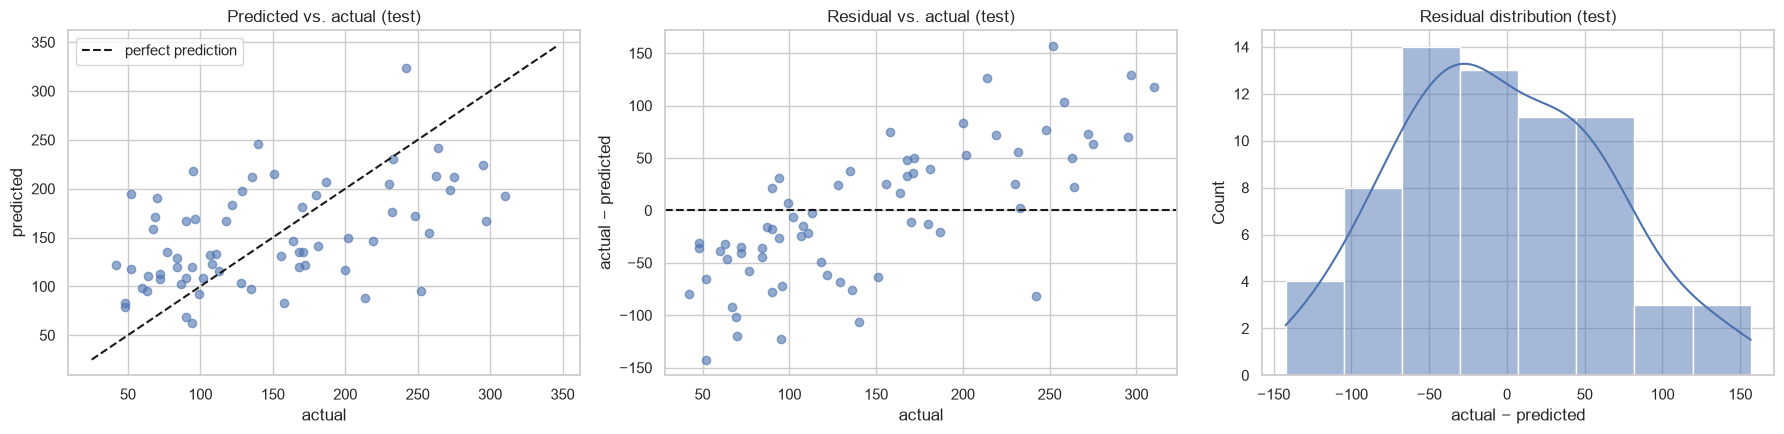

In [25]:
test_pred = best_bmi_model.predict(X_test_bmi)
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].scatter(y_test, test_pred, alpha=0.6)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", label="perfect prediction")
axes[0].set(title="Predicted vs. actual (test)", xlabel="actual", ylabel="predicted")
axes[0].legend()
axes[1].scatter(y_test, residuals, alpha=0.6)
axes[1].axhline(0, color="k", ls="--")
axes[1].set(title="Residual vs. actual (test)", xlabel="actual", ylabel="actual − predicted")
sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set(title="Residual distribution (test)", xlabel="actual − predicted")
fig.tight_layout()
plt.show()

In [26]:
target_band = pd.qcut(y_test, 3, labels=["low", "medium", "high"])
pd.DataFrame({"actual": y_test, "predicted": test_pred, "abs error": residuals.abs(),
              "APE (%)": 100 * residuals.abs() / y_test, "band": target_band}) \
    .groupby("band", observed=True).agg(n=("actual", "size"), mean_actual=("actual", "mean"),
                                        mean_predicted=("predicted", "mean"),
                                        MAE=("abs error", "mean"), MAPE=("APE (%)", "mean")).round(1)

,n,mean_actual,mean_predicted,MAE,MAPE
band,,,,,
low,23,72.3,124.8,57.1,86.4
medium,22,134.1,146.7,40.1,30.2
high,22,237.5,180.5,67.5,27.9


**Using it as a screening tool.** If I flag a patient as high risk whenever their predicted
progression is above the training median, how many of the truly high-risk patients do I catch?

In [27]:
from sklearn.metrics import confusion_matrix, classification_report

RISK_THRESHOLD = y_train.median()
actual_high = (y_test > RISK_THRESHOLD).astype(int)
flagged_high = (test_pred > RISK_THRESHOLD).astype(int)

print(f"Risk threshold (training median): {RISK_THRESHOLD}")
print(pd.DataFrame(confusion_matrix(actual_high, flagged_high),
                   index=["actual low", "actual high"], columns=["flagged low", "flagged high"]))
print(classification_report(actual_high, flagged_high, target_names=["low", "high"]))

Risk threshold (training median): 142.0
             flagged low  flagged high
actual low            25            12
actual high           10            20
              precision    recall  f1-score   support

         low       0.71      0.68      0.69        37
        high       0.62      0.67      0.65        30

    accuracy                           0.67        67
   macro avg       0.67      0.67      0.67        67
weighted avg       0.67      0.67      0.67        67



**What I found**
- **Predictions are pulled towards the middle.** The model over-predicts for patients with low
  progression and under-predicts for patients with high progression. For the lowest third of test
  patients it predicts about 52 points too high on average (MAPE ≈ 86%), and for the highest third it
  predicts about 57 points too low.
- **The biggest errors are in the high-progression group** (MAE ≈ 68). Unfortunately, those are exactly
  the patients a screening tool needs to catch.
- **MAPE is mostly driven by the low values.** A 50-point error on a patient whose true value is 40
  counts as 125%, so the high MAPE mostly comes from the low group.
- **Extreme BMI values** (like the test patient with BMI ≈ 42) are hard because there are very few
  training patients with a BMI that high.
- **As a screening tool** (using the training median as the cut-off), the model only catches **67% of
  the truly high-risk patients** (recall). That means 10 out of 30 high-risk patients would be missed.
  Also, 38% of the patients it flags are false alarms (precision 0.62). Overall accuracy is 67%.

### 14.2 Summary
- BMI is the strongest single predictor, and its relationship with progression is basically **linear**.
  Degree 1 does as well as degrees 2–5 with fewer parameters.
- My chosen model is $\widehat{\text{progression}} = -130.87 + 10.77 \times \text{BMI}$.
- On the test set it gets **R² ≈ 0.20, MAE ≈ 55 and MAPE ≈ 49%**. That's better than guessing the
  mean, but BMI alone only explains a small part of the variation in progression.

### 14.3 Limitations
- **One feature isn't enough for a disease with many causes.** Blood pressure, triglycerides (`ltg`)
  and HDL are also related to progression, and this model ignores them. I add them in Part 3.
- **The dataset is small, so the scores are noisy.** With only 45 validation and 67 test patients, the
  scores change a lot between splits (validation R² 0.45 vs. test 0.20). k-fold cross-validation would
  be more reliable.
- **Correlation isn't causation.** The slope shows a pattern in this group of patients. It doesn't mean
  that lowering someone's BMI by 1 would lower their progression by 10.8.
- **High-degree polynomials on raw BMI are numerically unstable** (BMI⁵ is around 10⁸), which is why
  their coefficients look strange. That's another reason I prefer the low-degree model.
- **It may not work as well on other people.** All 442 patients come from one study, so I don't know
  how well it would do on other populations.

### 14.4 Connecting to the workshops
- *Performance metrics:* R² and MAE tell me how accurate the model is on average, but for screening the
  **confusion matrix** matters more, especially **recall** for high-risk patients. If I lowered the
  risk threshold, I'd catch more at-risk patients but get more false alarms. That's usually worth it
  when a follow-up test is cheap.
- *Logistic regression:* if I treat the problem directly as high vs. low risk, logistic regression
  gives a **probability of high progression**, so I can tune the threshold for recall.
- *kNN:* a model like kNN that uses several (scaled) features might pick up patterns that a straight
  line on one feature can't, but I'd need to choose *k* carefully and scale the features.

# Part 3 – Multivariate models
## Feature selection

Based on what I found in the EDA:
- **I dropped `tc`** (total cholesterol). It's almost a copy of `ldl` (r ≈ 0.90) and only weakly
  related to the target (r ≈ 0.21). Keeping both doesn't add new information and can make the
  polynomial coefficients unstable.
- **I kept everything else**, including the weakly correlated `sex`, `age` and `ldl`. Correlation only
  measures straight-line relationships one feature at a time, so these features could still help when
  combined with others (for example, `sex` is related to `hdl` and `tch`), or in non-linear models like
  trees and kNN.

In [28]:
FEATURES = [c for c in X.columns if c != "tc"]
X_train_mv, X_val_mv, X_test_mv = X_train[FEATURES], X_val[FEATURES], X_test[FEATURES]
FEATURES

['age', 'sex', 'bmi', 'bp', 'ldl', 'hdl', 'tch', 'ltg', 'glu']

## 6. Models

I picked two settings for each type of model:

| Model type | Model A | Model B | Why I chose these |
|---|---|---|---|
| Polynomial regression | degree 2 | degree 3 | degree 2 adds squares and interactions; degree 3 tests whether even more flexibility helps |
| Decision tree | `max_depth=3` | `max_depth=5` | a shallow, simple tree vs. a deeper, more flexible one |
| kNN | `k=5` | `k=15` | few neighbours (more detailed but noisier) vs. more neighbours (smoother) |
| Logistic regression | `C=1` | `C=0.01` | the default vs. strong regularisation |

- I put a `StandardScaler` in the pipeline for the polynomial and kNN models. kNN needs it because it's
  based on distances. The polynomial models need it because raising differently-scaled features to
  powers gives huge, unstable numbers. Trees split on one feature at a time, so they don't need scaling.
- **Logistic regression is a classifier**, so I turned the target into a yes/no label:
  **high progression = above the training median** (142). I used the median from the training set only,
  so no information leaks in from the validation or test sets, and it gives two roughly equal-sized classes.

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LogisticRegression


def poly_model(degree):
    return Pipeline([("scale", StandardScaler()),
                     ("poly", PolynomialFeatures(degree=degree)),
                     ("linreg", LinearRegression())])


def knn_model(k):
    return Pipeline([("scale", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=k))])


def logistic_model(C):
    return Pipeline([("scale", StandardScaler()), ("logreg", LogisticRegression(C=C))])


mv_models = {
    "Polynomial (deg 2)": poly_model(2),
    "Polynomial (deg 3)": poly_model(3),
    "Tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "Tree (depth 5)": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    "kNN (k=5)": knn_model(5),
    "kNN (k=15)": knn_model(15),
}
for model in mv_models.values():
    model.fit(X_train_mv, y_train)

# Binary screening labels for logistic regression
y_train_cls = (y_train > RISK_THRESHOLD).astype(int)
y_val_cls = (y_val > RISK_THRESHOLD).astype(int)
y_test_cls = (y_test > RISK_THRESHOLD).astype(int)

log_models = {"Logistic (C=1)": logistic_model(1.0), "Logistic (C=0.01)": logistic_model(0.01)}
for model in log_models.values():
    model.fit(X_train_mv, y_train_cls)

print("Class balance (train):", y_train_cls.value_counts().to_dict())

Class balance (train): {0: 168, 1: 162}


## 7. Compare the models on training and validation data
### 7.1 Regression models (R², MAE, MAPE)

In [30]:
mv_results = compare_models(mv_models, X_train_mv, X_val_mv)
mv_results.round(3)

,Train R2,Train MAE,Train MAPE (%),Val R2,Val MAE,Val MAPE (%)
Polynomial (deg 2),0.582,40.205,35.662,0.547,39.738,43.550
Polynomial (deg 3),0.802,26.244,23.361,-2.042,87.433,81.991
Tree (depth 3),0.533,43.588,37.748,0.413,42.078,43.651
Tree (depth 5),0.702,33.406,29.331,0.184,49.724,51.230
kNN (k=5),0.597,39.199,33.962,0.412,46.684,47.461
kNN (k=15),0.509,44.139,39.179,0.569,39.167,39.858


### 7.2 Logistic regression (classification metrics)

R², MAE and MAPE don't work for yes/no labels, so for logistic regression I use the classification
metrics from the *Performance Metrics* workshop. **Recall** (the share of truly high-risk patients that
get flagged) is the most important one for screening. **ROC-AUC** shows how well the predicted
probabilities rank high-risk patients above low-risk ones, no matter which threshold I pick.

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


def classification_metrics(y_true, y_pred, y_score=None):
    metrics = {"Accuracy": accuracy_score(y_true, y_pred),
               "Precision": precision_score(y_true, y_pred),
               "Recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred)}
    if y_score is not None:
        metrics["ROC-AUC"] = roc_auc_score(y_true, y_score)
    return metrics


log_results = pd.DataFrame({
    name: {**{f"Train {k}": v for k, v in classification_metrics(
               y_train_cls, m.predict(X_train_mv), m.predict_proba(X_train_mv)[:, 1]).items()},
           **{f"Val {k}": v for k, v in classification_metrics(
               y_val_cls, m.predict(X_val_mv), m.predict_proba(X_val_mv)[:, 1]).items()}}
    for name, m in log_models.items()
}).T
log_results.round(3)

,Train Accuracy,Train Precision,Train Recall,Train F1,Train ROC-AUC,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC
Logistic (C=1),0.736,0.733,0.728,0.731,0.840,0.822,0.792,0.864,0.826,0.915
Logistic (C=0.01),0.730,0.724,0.728,0.726,0.824,0.844,0.826,0.864,0.844,0.925


### 7.3 All models as screening tools

To compare all eight models fairly, I also turn the regression predictions into high/low flags using
the same cut-off (predicted progression > 142).

In [32]:
screening = {}
for name, m in mv_models.items():
    screening[name] = classification_metrics(y_val_cls, (m.predict(X_val_mv) > RISK_THRESHOLD).astype(int))
for name, m in log_models.items():
    screening[name] = classification_metrics(y_val_cls, m.predict(X_val_mv))
screening_val = pd.DataFrame(screening).T.add_prefix("Val ")
screening_val.round(3)

,Val Accuracy,Val Precision,Val Recall,Val F1
Polynomial (deg 2),0.800,0.741,0.909,0.816
Polynomial (deg 3),0.578,0.560,0.636,0.596
Tree (depth 3),0.800,0.760,0.864,0.809
Tree (depth 5),0.733,0.727,0.727,0.727
kNN (k=5),0.711,0.680,0.773,0.723
kNN (k=15),0.778,0.731,0.864,0.792
Logistic (C=1),0.822,0.792,0.864,0.826
Logistic (C=0.01),0.844,0.826,0.864,0.844


**What I noticed**
- **Polynomial degree 3 overfits badly.** With 9 features it creates 220 terms, but there are only 330
  training patients. It gets a train R² of about 0.80, but its validation R² is about −2, which is much
  worse than just predicting the mean.
- **The depth-5 tree also overfits** (train R² ≈ 0.70 vs. validation ≈ 0.18). The depth-3 tree
  generalises better.
- **kNN with k = 15** has the best validation scores, and it doesn't get worse from train to validation.
  kNN with k = 5 fits the training data more closely but does worse on validation. This is the
  bias–variance trade-off from the kNN workshop.
- **Polynomial degree 2** comes a close second.
- **Logistic regression** gets about 82–84% validation accuracy, a recall of about 0.86 and a ROC-AUC of
  about 0.92. The two C values give almost the same results, so the model isn't overfitting and
  regularisation doesn't change much.
- **As screening tools** (table 7.3), logistic regression with C = 0.01 has the best accuracy, precision
  and F1. Polynomial degree 2 has the highest recall (0.91), so it misses the fewest high-risk patients,
  but it also raises more false alarms. There are only 22 high-risk patients in the validation set, so
  one patient changes recall by about 0.05. These differences are small.

## 8. Identify the best models

In [33]:
print("Best regression model by validation metric:")
print("  R²  :", mv_results["Val R2"].idxmax())
print("  MAE :", mv_results["Val MAE"].idxmin())
print("  MAPE:", mv_results["Val MAPE (%)"].idxmin())
print("Best logistic model by validation accuracy / F1:",
      log_results["Val Accuracy"].idxmax(), "/", log_results["Val F1"].idxmax())

Best regression model by validation metric:
  R²  : kNN (k=15)
  MAE : kNN (k=15)
  MAPE: kNN (k=15)
Best logistic model by validation accuracy / F1: Logistic (C=0.01) / Logistic (C=0.01)


- **Best regression model: kNN (k = 15).** It wins on all three validation metrics (R² ≈ 0.57,
  MAE ≈ 39.2, MAPE ≈ 39.9%). Unlike the deeper tree and the degree-3 polynomial, it doesn't overfit;
  its validation score is even higher than its training score.
- **Best classifier: logistic regression (C = 0.01).** It has the same recall and ROC-AUC as C = 1, but
  higher accuracy, precision and F1. The stronger regularisation also makes it the simpler, more stable model.

I take both to the test set: kNN for predicting the progression *score*, and logistic regression for
the *high-risk / low-risk* screening decision.

In [34]:
best_mv_name, best_log_name = "kNN (k=15)", "Logistic (C=0.01)"
best_mv_model, best_log_model = mv_models[best_mv_name], log_models[best_log_name]

## 9. Evaluate the chosen models on the test set

In [35]:
mv_test_results = pd.DataFrame({
    "BMI only – degree 1 (Part 2)": regression_metrics(y_test, best_bmi_model.predict(X_test_bmi)),
    f"{best_mv_name} – train": regression_metrics(y_train, best_mv_model.predict(X_train_mv)),
    f"{best_mv_name} – validation": regression_metrics(y_val, best_mv_model.predict(X_val_mv)),
    f"{best_mv_name} – test": regression_metrics(y_test, best_mv_model.predict(X_test_mv)),
}).T
mv_test_results.round(3)

,R2,MAE,MAPE (%)
BMI only – degree 1 (Part 2),0.204,54.934,48.750
kNN (k=15) – train,0.509,44.139,39.179
kNN (k=15) – validation,0.569,39.167,39.858
kNN (k=15) – test,0.409,45.215,40.617


In [36]:
log_test_pred = best_log_model.predict(X_test_mv)
log_test_proba = best_log_model.predict_proba(X_test_mv)[:, 1]

pd.DataFrame({
    "BMI only – degree 1 (Part 2)": classification_metrics(y_test_cls, flagged_high),
    f"{best_mv_name} (flag > {RISK_THRESHOLD:.0f})": classification_metrics(
        y_test_cls, (best_mv_model.predict(X_test_mv) > RISK_THRESHOLD).astype(int)),
    best_log_name: classification_metrics(y_test_cls, log_test_pred, log_test_proba),
}).T.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
BMI only – degree 1 (Part 2),0.672,0.625,0.667,0.645,NaN
kNN (k=15) (flag > 142),0.761,0.694,0.833,0.758,NaN
Logistic (C=0.01),0.776,0.759,0.733,0.746,0.833


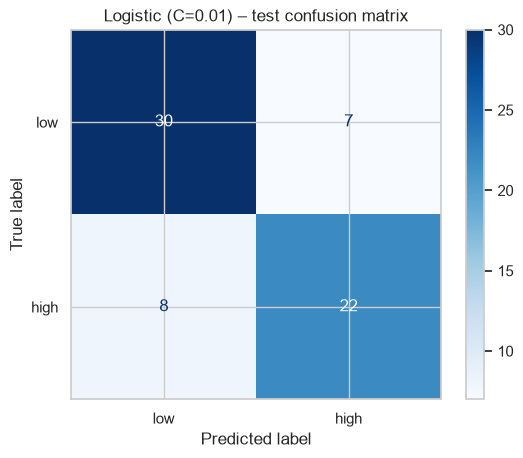

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test_cls, log_test_pred, display_labels=["low", "high"],
                                        cmap="Blues")
plt.title(f"{best_log_name} – test confusion matrix")
plt.show()

**Test results**
- **kNN (k = 15): R² ≈ 0.41, MAE ≈ 45, MAPE ≈ 41%.** Using all the selected features roughly
  **doubles R²** compared with BMI alone (0.20) and lowers the average error by about 10 points. The
  test scores are close to the training scores, so the model isn't overfitting. Like in Part 2, the
  validation scores were a bit optimistic.
- **Logistic regression (C = 0.01): accuracy ≈ 78%, ROC-AUC ≈ 0.83, recall ≈ 0.73.** It flags 22 of the
  30 high-risk test patients and misses 8.
- Something I didn't expect: **kNN used as a screener has a higher test recall (0.83)**. It only misses
  5 of the 30 high-risk patients, while logistic regression has better precision (fewer false alarms).
  Since missing a high-risk patient is the worse mistake, this points towards kNN, or towards logistic
  regression with a *lower* probability threshold.
- Both multivariate models beat the BMI-only model on every metric.

## 10. Plots

I can't draw a fitted line on one axis for a model with 9 features (and plots aren't required for the
multivariate models). Instead I show **predicted vs. actual** for kNN and the **ROC curve** for
logistic regression on the test set.

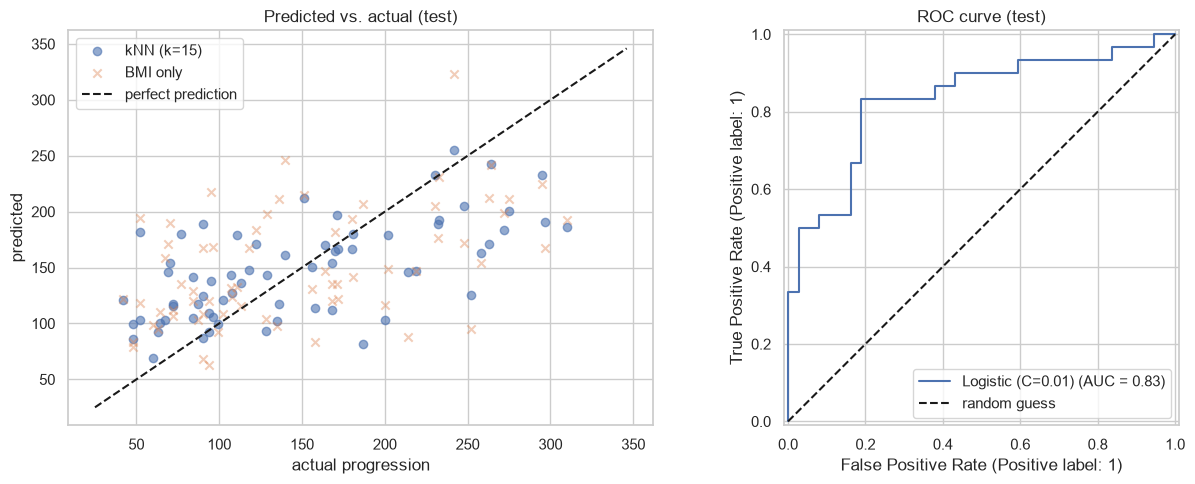

In [38]:
from sklearn.metrics import RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, best_mv_model.predict(X_test_mv), alpha=0.6, label=best_mv_name)
axes[0].scatter(y_test, best_bmi_model.predict(X_test_bmi), alpha=0.4, marker="x", label="BMI only")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", label="perfect prediction")
axes[0].set(title="Predicted vs. actual (test)", xlabel="actual progression", ylabel="predicted")
axes[0].legend()
RocCurveDisplay.from_predictions(y_test_cls, log_test_proba, name=best_log_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="random guess")
axes[1].set_title("ROC curve (test)")
axes[1].legend()
fig.tight_layout()
plt.show()

- The kNN predictions are closer to the diagonal than the BMI-only predictions, but they only go from
  about 70 to 255. Because kNN averages 15 neighbours, it can never predict a really extreme value, so
  patients with very high progression (> 250) are still under-predicted.
- From the ROC curve, at a false-positive rate of about 20% the logistic model already catches about
  83% of the high-risk patients. Lowering the threshold moves along this curve towards higher recall.

## 11. Model equations

**kNN doesn't have an equation.** It's a *non-parametric* model: to predict a new patient, it finds the
15 most similar training patients (by distance on the scaled features) and averages their target values:

$$\widehat{\text{progression}}(x) = \frac{1}{15}\sum_{i \in N_{15}(x)} y_i$$

**Logistic regression** does have an equation. Here it is on the standardised features
$z_j = (x_j - \mu_j)/\sigma_j$:

In [39]:
logreg = best_log_model.named_steps["logreg"]
log_coefs = pd.Series(logreg.coef_[0], index=FEATURES)

terms = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):.2f}·z_{name}" for name, c in log_coefs.items())
print(f"log-odds(high progression) = {logreg.intercept_[0]:.2f} {terms}")
print("P(high progression) = 1 / (1 + exp(-log-odds))\n")
log_coefs.sort_values(key=abs, ascending=False).round(2).to_frame("coefficient (standardised)")

log-odds(high progression) = -0.04 + 0.09·z_age - 0.14·z_sex + 0.28·z_bmi + 0.22·z_bp - 0.03·z_ldl - 0.16·z_hdl + 0.12·z_tch + 0.25·z_ltg + 0.13·z_glu
P(high progression) = 1 / (1 + exp(-log-odds))



,coefficient (standardised)
bmi,0.28
ltg,0.25
bp,0.22
hdl,-0.16
sex,-0.14
glu,0.13
tch,0.12
age,0.09
ldl,-0.03


Because the features are standardised, I can compare the coefficients directly. Each one is the change
in the log-odds of high progression when that feature goes up by one standard deviation.

- **BMI, `ltg` and blood pressure** increase the risk the most, and **`hdl`** lowers it. This matches
  what the correlation matrix showed in the EDA.
- `sex` has a noticeable weight (−0.14) even though its correlation with the target was about 0. It only
  matters *in combination* with the other features, which supports my decision to keep it.
- The coefficients are small because the strong regularisation (C = 0.01) shrinks them all towards 0.

## 12. Prediction for an example patient

To compare with Part 2, I made up a "typical" patient by using the training-set median for every
feature, and then set **BMI = 30**.

In [40]:
patient = X_train_mv.median().to_frame().T
patient["bmi"] = 30.0
display(patient)

print(f"BMI-only model (Part 2):      {best_bmi_model.predict(patient[['bmi']])[0]:.2f}")
print(f"{best_mv_name}:                  {best_mv_model.predict(patient)[0]:.2f}")
print(f"{best_log_name} P(high risk): {best_log_model.predict_proba(patient)[0, 1]:.2f}")

,age,sex,bmi,bp,ldl,hdl,tch,ltg,glu
0,50.0,0.0,30.0,93.0,112.3,48.0,4.0,4.63,91.0


BMI-only model (Part 2):      192.17
kNN (k=15):                  170.80
Logistic (C=0.01) P(high risk): 0.58


All three models put this patient above the risk cut-off (142), but the multivariate models are less
extreme. kNN predicts about 171 (compared with 192 from BMI alone), and logistic regression gives a 58%
chance of high progression. This patient's other values (blood pressure, triglycerides, HDL) are
average, which pulls the prediction back towards the middle. The BMI-only model can't use that information.

## 13. Number of trainable parameters per model

In [41]:
def count_parameters(name, model):
    if "Polynomial" in name:
        n = model.named_steps["poly"].get_feature_names_out(FEATURES).size
        return n, f"{n} polynomial terms (incl. bias '1'), one weight each"
    if "Tree" in name:
        splits = model.tree_.node_count - model.get_n_leaves()
        leaves = model.get_n_leaves()
        return 2 * splits + leaves, f"{splits} splits × (feature, threshold) + {leaves} leaf values"
    if "kNN" in name:
        return 0, f"nothing learned – stores all {len(X_train_mv)} × {len(FEATURES)} training values"
    if "Logistic" in name:
        lr = model.named_steps["logreg"]
        return lr.coef_.size + lr.intercept_.size, f"{lr.coef_.size} weights + 1 intercept"


param_rows = {name: count_parameters(name, m) for name, m in {**mv_models, **log_models}.items()}
pd.DataFrame(param_rows, index=["trainable parameters", "explanation"]).T

,trainable parameters,explanation
Polynomial (deg 2),55,"55 polynomial terms (incl. bias '1'), one weig..."
Polynomial (deg 3),220,"220 polynomial terms (incl. bias '1'), one wei..."
Tree (depth 3),22,"7 splits × (feature, threshold) + 8 leaf values"
Tree (depth 5),94,"31 splits × (feature, threshold) + 32 leaf values"
kNN (k=5),0,nothing learned – stores all 330 × 9 training ...
kNN (k=15),0,nothing learned – stores all 330 × 9 training ...
Logistic (C=1),10,9 weights + 1 intercept
Logistic (C=0.01),10,9 weights + 1 intercept


In [42]:
print("First 12 degree-2 terms:", mv_models["Polynomial (deg 2)"].named_steps["poly"]
      .get_feature_names_out(FEATURES)[:12])

First 12 degree-2 terms: ['1' 'age' 'sex' 'bmi' 'bp' 'ldl' 'hdl' 'tch' 'ltg' 'glu' 'age^2'
 'age sex']


- **Polynomial:** with $p = 9$ features, a degree-$d$ polynomial has $\binom{p+d}{d}$ terms. That
  includes the bias, every feature, every square and every product of features. So degree 2 has **55**
  terms and degree 3 has **220**. The bias column and `LinearRegression`'s intercept do the same job, so
  I count the number of terms. Having 220 parameters for only 330 training patients explains why
  degree 3 overfits so badly.
- **Decision tree:** at each split, the tree learns which feature to split on and the threshold value,
  and each leaf stores a predicted value. The depth-5 tree has many more leaves than the depth-3 tree,
  so it can memorise small groups of patients.
- **kNN:** **0 trainable parameters.** It's a *lazy learner*: "training" just stores the data, and all
  the work happens when it makes a prediction. *k* is a hyperparameter that I chose, not something it learns.
- **Logistic regression:** one weight per feature plus an intercept, so **10**.
- (The `StandardScaler` also learns a mean and standard deviation for each feature, but those are just
  preprocessing statistics, not weights trained to predict the target.)

## 14. Conclusions – Part 3
### 14.1 Where do the models fail?

To see where the models go wrong, I look at kNN's errors for low, medium and high progression, and at
the high-risk patients that logistic regression missed.

In [43]:
knn_test_pred = best_mv_model.predict(X_test_mv)
pd.DataFrame({"actual": y_test, "predicted": knn_test_pred,
              "abs error": (y_test - knn_test_pred).abs(),
              "APE (%)": 100 * (y_test - knn_test_pred).abs() / y_test, "band": target_band}) \
    .groupby("band", observed=True).agg(n=("actual", "size"), mean_actual=("actual", "mean"),
                                        mean_predicted=("predicted", "mean"),
                                        MAE=("abs error", "mean"), MAPE=("APE (%)", "mean")).round(1)

,n,mean_actual,mean_predicted,MAE,MAPE
band,,,,,
low,23,72.3,120.6,48.7,75.2
medium,22,134.1,141.9,27.0,20.7
high,22,237.5,179.2,59.8,24.4


In [44]:
missed = X_test_mv.assign(actual=y_test, p_high=log_test_proba)[(y_test_cls == 1) & (log_test_pred == 0)]
print(f"High-risk patients missed by {best_log_name}: {len(missed)} of {y_test_cls.sum()}")
missed.sort_values("actual").round(2)

High-risk patients missed by Logistic (C=0.01): 8 of 30


,age,sex,bmi,bp,ldl,hdl,tch,ltg,glu,actual,p_high
284,60.0,1,24.3,103.0,86.6,33.0,4.0,4.67,78.0,156.0,0.50
131,22.0,0,19.9,75.0,108.6,54.0,3.0,4.13,72.0,158.0,0.19
19,41.0,0,24.7,83.0,108.2,60.0,3.0,4.54,78.0,168.0,0.34
244,32.0,1,31.4,89.0,84.2,56.0,3.0,4.16,90.0,187.0,0.39
77,22.0,0,23.0,73.0,97.8,54.0,3.0,3.83,91.0,200.0,0.23
218,37.0,0,20.3,83.0,124.6,38.0,5.0,4.72,88.0,214.0,0.41
78,50.0,0,21.0,88.0,71.8,35.0,4.0,5.11,71.0,252.0,0.47
395,32.0,0,26.5,86.0,101.6,53.0,4.0,4.99,78.0,258.0,0.46


In [45]:
print("Median of missed patients vs. all high-risk test patients:")
pd.DataFrame({"missed": missed[["bmi", "bp", "ltg", "hdl", "actual"]].median(),
              "all high-risk": X_test_mv[y_test_cls == 1][["bmi", "bp", "ltg", "hdl"]].median()
                               .reindex(["bmi", "bp", "ltg", "hdl", "actual"])
                               .fillna(y_test[y_test_cls == 1].median())}).round(2)

Median of missed patients vs. all high-risk test patients:


,missed,all high-risk
bmi,23.65,27.90
bp,84.50,100.00
ltg,4.61,4.97
hdl,53.50,43.50
actual,193.50,216.50


**Changing the threshold.** By default, logistic regression flags a patient when P(high) > 0.5.
For screening I can lower this. I compare thresholds on the **validation** set and then check them on
the test set:

In [46]:
val_proba = best_log_model.predict_proba(X_val_mv)[:, 1]
rows = []
for t in [0.5, 0.4, 0.3]:
    for split, y_true, proba in [("validation", y_val_cls, val_proba), ("test", y_test_cls, log_test_proba)]:
        pred = (proba > t).astype(int)
        rows.append({"threshold": t, "split": split, "recall": recall_score(y_true, pred),
                     "precision": precision_score(y_true, pred), "accuracy": accuracy_score(y_true, pred),
                     "missed high-risk": int(((y_true == 1) & (pred == 0)).sum())})
pd.DataFrame(rows).set_index(["threshold", "split"]).round(3)

recall  precision  accuracy  missed high-risk
threshold split                                                    
0.5       validation   0.864      0.826     0.844                 3
          test         0.733      0.759     0.776                 8
0.4       validation   0.909      0.606     0.667                 2
          test         0.867      0.634     0.716                 4
0.3       validation   1.000      0.564     0.622                 0
          test         0.933      0.509     0.567                 2

**What I found**
- **kNN still pulls predictions towards the middle.** It predicts about 48 points too high for the
  lowest third of patients (MAPE ≈ 75%) and about 58 points too low for the highest third. It's much
  better than BMI alone for the middle group (MAE 27 vs. 40), but the **highest-risk patients are still
  the hardest to predict**.
- **The high-risk patients that were missed look "healthy" on paper.** Compared with the typical
  high-risk patient, the 8 patients logistic regression missed have a lower BMI (about 23.7 vs. 27.9),
  lower blood pressure, lower triglycerides and higher HDL. Something not in these 10 measurements is
  driving their progression (for example medication, lifestyle or genetics), so no model trained on
  this data can reliably find them.
- **Many of the misses were close calls:** 6 of the 8 had a predicted probability between 0.34 and 0.50.
  Lowering the threshold to 0.4 (chosen on the validation set) halves the misses on the test set
  (8 → 4, recall 0.73 → 0.87), but precision drops (0.76 → 0.63).
- **Flexible models overfit with this little data:** polynomial degree 3 (220 parameters) and the depth-5
  tree memorise the training set and do worse than simpler models on validation.

### 14.2 Summary of all models

| Model | Val R² | Val MAE | Notes |
|---|---|---|---|
| BMI only, degree 1 (Part 2) | 0.45 | 42.0 | test R² 0.20 – weak on its own |
| Polynomial deg 2 | 0.55 | 39.7 | close second; 55 parameters |
| Polynomial deg 3 | −2.04 | 87.4 | overfits badly |
| Tree depth 3 | 0.41 | 42.1 | easy to interpret, but too simple |
| Tree depth 5 | 0.18 | 49.7 | overfits |
| kNN k=5 | 0.41 | 46.7 | too sensitive to individual neighbours |
| **kNN k=15** | **0.57** | **39.2** | **best regression model – test R² 0.41, MAE 45, MAPE 41%** |
| Logistic C=1 | – | – | val accuracy 0.82, recall 0.86 |
| **Logistic C=0.01** | – | – | **best classifier – test accuracy 0.78, recall 0.73, ROC-AUC 0.83** |

Using several features roughly **doubles the explained variance** compared with BMI alone (test R²
0.20 → 0.41). For the screening goal, I think **logistic regression with a lower threshold (about 0.4)**
is the most practical choice: it gives a risk probability that's easy to explain, it only has 10
parameters, and it catches about 87% of the high-risk test patients.

### 14.3 Limitations
- **The dataset is small** (442 patients; 45 in validation, 67 in test). The scores change noticeably
  between splits, and validation was optimistic for every model. k-fold cross-validation and a proper
  hyperparameter search (for example over *k* or `max_depth`) would give more reliable choices.
- **Only about 40% of the variation is explained.** A lot of what drives disease progression isn't in
  this dataset.
- **The high/low label is an arbitrary cut** at the median (142). A cut-off chosen by doctors would
  change the results, and patients just above and just below 142 are almost the same but get different labels.
- **kNN is hard for doctors to interpret** (there are no coefficients), it has to keep the whole training
  set, and it would get slower and less accurate with many more patients or features (the curse of
  dimensionality).
- **Correlation isn't causation**, and all the data comes from one study. These models should support a
  doctor's judgement, not replace it, and they would need to be tested on other populations.

### 14.4 Connecting to the workshops
- *Performance metrics:* accuracy alone hides *which* mistakes are made. The confusion matrix and
  **recall** show that the default logistic model misses 8 of 30 at-risk patients. For screening, a false
  negative is worse than a false positive, so I deliberately traded some precision for recall by
  lowering the threshold. ROC-AUC (0.83) summarises how well the model ranks patients across all thresholds.
- *k-Nearest Neighbours:* scaling was essential (the features range from about 4 to about 190). k = 5
  followed the training data too closely, and k = 15 smoothed out the noise and generalised best. kNN
  has no trainable parameters because it's a lazy learner.
- *Logistic regression:* it models the probability of high progression using the sigmoid of a linear
  score. The standardised coefficients agree with the EDA (BMI, `ltg` and `bp` increase risk; `hdl`
  lowers it), and changing C barely mattered, which means the model wasn't overfitting.